# Parameters

In [1]:
MARKET_TICKERS = {
    "india": [
        "RELIANCE.NS", "TCS.NS", "HDFCBANK.NS", "INFY.NS", "ICICIBANK.NS",
        "HINDUNILVR.NS", "ITC.NS", "SBIN.NS", "BHARTIARTL.NS", "LT.NS",
        "KOTAKBANK.NS", "AXISBANK.NS", "BAJFINANCE.NS", "ASIANPAINT.NS", "MARUTI.NS",
        "HCLTECH.NS", "SUNPHARMA.NS", "WIPRO.NS", "ULTRACEMCO.NS", "TITAN.NS",
        "TECHM.NS", "NESTLEIND.NS", "POWERGRID.NS", "NTPC.NS", "ONGC.NS",
        "JSWSTEEL.NS", "TATASTEEL.NS", "HINDALCO.NS", "COALINDIA.NS", "DIVISLAB.NS",
        "DRREDDY.NS", "CIPLA.NS", "ADANIENT.NS", "ADANIPORTS.NS", "BAJAJFINSV.NS",
        "BAJAJ-AUTO.NS", "HEROMOTOCO.NS", "EICHERMOT.NS", "TATACONSUM.NS", "BRITANNIA.NS",
        "GRASIM.NS", "INDUSINDBK.NS", "M&M.NS", "SBILIFE.NS", "HDFCLIFE.NS",
        "PIDILITIND.NS", "HAVELLS.NS", "SIEMENS.NS", "ABB.NS", "BERGEPAINT.NS",
    ],
    "usa": [
        "AAPL", "MSFT", "GOOGL", "AMZN", "NVDA", "META", "TSLA", "BRK-B", "UNH", "JNJ",
        "JPM", "V", "PG", "XOM", "HD", "CVX", "MRK", "ABBV", "PEP", "KO",
        "LLY", "AVGO", "COST", "MCD", "CSCO", "TMO", "ACN", "ABT", "DHR", "NEE",
        "TXN", "WMT", "PM", "QCOM", "HON", "UPS", "AMGN", "IBM", "SBUX", "GE",
        "MMM", "CAT", "BA", "GS", "MS", "BLK", "SPGI", "AXP", "RTX", "LMT",
    ],
    "europe": [
        "ASML.AS", "LVMH.PA", "NESN.SW", "NOVN.SW", "ROG.SW",
        "SAP.DE", "SIE.DE", "ALV.DE", "BAS.DE", "BAYN.DE",
        "AIR.PA", "BNP.PA", "MC.PA", "SAN.PA", "OR.PA",
        "SHELL.AS", "HEIA.AS", "PHIA.AS", "ING.AS", "UNA.AS",
        "AZN.L", "HSBA.L", "ULVR.L", "GSK.L", "RIO.L",
        "ENI.MI", "ENEL.MI", "ISP.MI", "UCG.MI", "STM.MI",
        "IBE.MC", "SAN.MC", "BBVA.MC", "ITX.MC", "REP.MC",
        "NOVO-B.CO", "DSV.CO", "ORSTED.CO", "NESTE.HE", "NOKIA.HE",
        "ERIC-B.ST", "VOLV-B.ST", "ATCO-A.ST", "ABB.ST", "SEB-A.ST",
        "LONN.SW", "GIVN.SW", "GEBN.SW", "CFR.SW", "SREN.SW",
    ],
    "japan": [
        "7203.T", "6758.T", "9984.T", "6861.T", "8306.T",
        "7974.T", "4063.T", "6098.T", "9433.T", "8035.T",
        "6954.T", "2914.T", "4519.T", "7751.T", "6301.T",
        "5108.T", "8801.T", "9022.T", "3382.T", "4543.T",
        "7267.T", "6902.T", "4661.T", "8411.T", "8316.T",
        "6702.T", "4502.T", "7832.T", "9613.T", "6503.T",
        "2802.T", "8766.T", "6273.T", "4523.T", "7011.T",
        "8053.T", "2501.T", "5401.T", "3407.T", "4568.T",
        "9432.T", "8031.T", "7733.T", "6645.T", "7201.T",
        "4901.T", "8002.T", "6971.T", "1925.T", "9020.T",
    ],
    "crypto": [
        "BTC-USD", "ETH-USD", "BNB-USD", "SOL-USD", "XRP-USD",
        "ADA-USD", "AVAX-USD", "DOGE-USD", "DOT-USD", "LINK-USD",
        "MATIC-USD", "LTC-USD", "BCH-USD", "ATOM-USD", "UNI-USD",
        "XLM-USD", "ALGO-USD", "VET-USD", "ICP-USD", "FIL-USD",
        "AAVE-USD", "EOS-USD", "XTZ-USD", "SAND-USD", "MANA-USD",
        "THETA-USD", "AXS-USD", "EGLD-USD", "FTM-USD", "NEAR-USD",
        "GALA-USD", "ENJ-USD", "CHZ-USD", "BAT-USD", "ZIL-USD",
        "WAVES-USD", "ICX-USD", "ZEC-USD", "DASH-USD", "XEM-USD",
        "QTUM-USD", "ONT-USD", "ZRX-USD", "BAL-USD", "CRV-USD",
        "SUSHI-USD", "YFI-USD", "COMP-USD", "MKR-USD", "SNX-USD",
    ],
}

MARKET_BENCHMARKS = {
    "india":  "^NSEI",
    "usa":    "^GSPC",
    "europe": "^STOXX50E",
    "japan":  "^N225",
    "crypto": "BTC-USD",
}

In [2]:
UNIVERSE_SIZES = {
    "small":  10,
    "medium": 25,
    "large":  50,
    "xlarge": 75,
}

# Core Functions

In [ ]:
import numpy as np
import pandas as pd
import yfinance as yf
import cvxpy as cp
import dimod
import neal
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
from typing import Dict, List, Tuple
from sklearn.covariance import LedoitWolf
import os
import warnings
import hashlib
import itertools
import seaborn as sns

warnings.filterwarnings('ignore')

In [4]:
# Configure logging to both console and file
import logging.handlers

# Create logs directory if it doesn't exist
log_dir = "logs"
os.makedirs(log_dir, exist_ok=True)

# Create logger
logger = logging.getLogger('qubo_optimization')
logger.setLevel(logging.DEBUG)

# Remove any existing handlers to avoid duplicates
logger.handlers.clear()

# Log file path with timestamp
log_timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
log_file = os.path.join(log_dir, f"qubo_optimization_{log_timestamp}.log")

# Create formatters
console_formatter = logging.Formatter('%(asctime)s - %(levelname)s - %(message)s', datefmt='%H:%M:%S')
file_formatter = logging.Formatter('%(asctime)s - %(name)s - %(levelname)s - %(message)s')

# Console handler (INFO and above)
console_handler = logging.StreamHandler()
console_handler.setLevel(logging.INFO)
console_handler.setFormatter(console_formatter)

# File handler (DEBUG and above)
file_handler = logging.FileHandler(log_file)
file_handler.setLevel(logging.DEBUG)
file_handler.setFormatter(file_formatter)

# Add handlers to logger
logger.addHandler(console_handler)
logger.addHandler(file_handler)

logger.info(f"Logging initialized - Console: INFO+, File: DEBUG+ ({log_file})")

15:15:23 - INFO - Logging initialized - Console: INFO+, File: DEBUG+ (logs\qubo_optimization_20260329_151523.log)


In [5]:
def download_data(market, start_date, end_date, cache_dir="data_cache"):
    os.makedirs(cache_dir, exist_ok=True)
    key = hashlib.md5(f"{market}_{start_date}_{end_date}".encode()).hexdigest()[:8]
    cache_path = os.path.join(cache_dir, f"{market}_{key}.csv")

    if os.path.exists(cache_path):
        return pd.read_csv(cache_path, index_col=0, parse_dates=True)

    tickers = MARKET_TICKERS[market]
    raw = yf.download(tickers, start=start_date, end=end_date, auto_adjust=True, progress=False)

    if raw.empty:
        raise ValueError(f"No data for market: {market}")

    prices = raw["Close"] if isinstance(raw.columns, pd.MultiIndex) else raw[["Close"]]
    prices = prices.dropna(axis=1, thresh=int(0.8 * len(prices)))
    prices = prices.dropna()

    prices.to_csv(cache_path)
    return prices

In [6]:
def sample_universe(prices, size, seed=42):
    n = min(size, prices.shape[1])
    rng = np.random.RandomState(seed)
    chosen = rng.choice(prices.columns.tolist(), size=n, replace=False)
    return prices[sorted(chosen)]

In [7]:
def compute_statistics(prices: pd.DataFrame, use_shrinkage: bool = True) -> Tuple[np.ndarray, np.ndarray, pd.DataFrame]:
    returns = prices.pct_change().dropna()

    mu = returns.mean().values * 252

    if use_shrinkage and len(returns) > len(returns.columns):
        lw = LedoitWolf()
        cov = lw.fit(returns).covariance_ * 252
    else:
        cov = returns.cov().values * 252

    logger.debug(f"Statistics: mu=[{mu.min():.4f}, {mu.max():.4f}], vol=[{np.sqrt(np.diag(cov)).min():.4f}, {np.sqrt(np.diag(cov)).max():.4f}], method={'Ledoit-Wolf' if use_shrinkage else 'Sample'}")

    return mu, cov, returns

In [8]:
def compute_lambda(mu: np.ndarray, cov: np.ndarray, q: float, B: int,
                   alpha: float = 5.0) -> float:
    mu_scale = np.max(np.abs(mu))
    lambda_penalty = max(
        alpha * mu_scale * B,
        2 * np.max(np.abs(cov))
    )
    logger.debug(f"compute_lambda: max_mu={mu_scale:.4f}, max_cov={np.max(np.abs(cov)):.4f}, B={B}, lambda={lambda_penalty:.4f}")
    return lambda_penalty


def enforce_cardinality(x: np.ndarray, scores: np.ndarray, B: int) -> np.ndarray:
    x_enforced = x.copy()
    selected_idx = np.where(x_enforced == 1)[0]
    unselected_idx = np.where(x_enforced == 0)[0]
    num_selected = len(selected_idx)

    if num_selected > B:
        worst = np.argsort(scores[selected_idx])[:num_selected - B]
        x_enforced[selected_idx[worst]] = 0
    elif num_selected < B:
        if len(unselected_idx) > 0:
            best = np.argsort(scores[unselected_idx])[-(B - num_selected):]
            x_enforced[unselected_idx[best]] = 1

    return x_enforced


def energy_check(Q: np.ndarray, B: int):
    """Check if QUBO penalizes cardinality violations via lambda penalty.
    
    Returns:
        e_B: Energy at cardinality B
        e_more: Energy at cardinality B+2  
        constraint_active: Boolean indicating if constraint is properly active (e_B < e_more)
    """
    n = Q.shape[0]
    x_B = np.zeros(n); x_B[:B] = 1
    x_more = np.zeros(n); x_more[:B + 2] = 1
    
    e_B = x_B @ Q @ x_B
    e_more = x_more @ Q @ x_more
    constraint_active = e_B < e_more  # True if constraint is properly penalizing violations
    
    logger.debug(f"energy_check: B={B}, E(B)={e_B:.4f}, E(B+2)={e_more:.4f}, active={constraint_active}")
    if not constraint_active:
        logger.warning(f"Weak energy constraint: E(B)={e_B:.4f} >= E(B+2)={e_more:.4f} - consider increasing lambda")
    
    return e_B, e_more, constraint_active

In [9]:
def build_qubo(mu: np.ndarray, cov: np.ndarray, q: float = 0.5,
               lambda_penalty: float = 10.0, B: int = 5) -> Tuple[np.ndarray, Tuple[float, float]]:
    n = len(mu)

    mu_norm = mu / np.maximum(np.max(np.abs(mu)), 1e-10)
    cov_norm = cov / np.maximum(np.max(np.abs(cov)), 1e-10)

    Q = q * cov_norm.copy()

    for i in range(n):
        Q[i, i] -= mu_norm[i]

    for i in range(n):
        Q[i, i] += lambda_penalty * (1 - 2 * B)
        for j in range(i + 1, n):
            Q[i, j] += 2 * lambda_penalty
            Q[j, i] += 2 * lambda_penalty

    q_scale = np.max(np.abs(Q))
    beta_range = (0.1 / q_scale, 5.0 / q_scale) if q_scale > 1e-10 else (0.1, 5.0)

    diag_min, diag_max = Q.diagonal().min(), Q.diagonal().max()
    offdiag_range = Q[np.triu_indices(n, k=1)]
    offdiag_min, offdiag_max = offdiag_range.min(), offdiag_range.max()
    
    logger.debug(f"build_qubo: shape={Q.shape}, diag=[{diag_min:.4f}, {diag_max:.4f}], offdiag=[{offdiag_min:.4f}, {offdiag_max:.4f}], beta_range=[{beta_range[0]:.4f}, {beta_range[1]:.4f}]")

    return Q, beta_range

In [10]:
def solve_qubo_sa(Q: np.ndarray, num_reads: int = 1000, B: int = 5,
                  seed: int = 42, beta_range: Tuple[float, float] = (0.1, 5.0),
                  n_seeds: int = 5, num_sweeps: int = 1000, warm_start: np.ndarray = None) -> Tuple[np.ndarray, float, int, int]:
    n = Q.shape[0]

    qubo_dict = {
        (i, j): Q[i, j]
        for i in range(n)
        for j in range(i, n)
        if Q[i, j] != 0
    }

    bqm = dimod.BinaryQuadraticModel.from_qubo(qubo_dict)
    sampler = neal.SimulatedAnnealingSampler()

    all_solutions = []

    for s in range(n_seeds):
        kwargs = dict(
            num_reads=num_reads,
            seed=seed + s,
            beta_range=list(beta_range),
            num_sweeps=num_sweeps
        )

        if warm_start is not None:
            init_sample = {i: int(warm_start[i]) for i in range(n)}
            kwargs['initial_states'] = [init_sample]

        sampleset = sampler.sample(bqm, **kwargs)
        best = sampleset.first
        sol = np.array([best.sample.get(i, 0) for i in range(n)])
        all_solutions.append(sol)

    vote = np.mean(all_solutions, axis=0)
    solution = (vote >= 0.5).astype(int)

    num_selected = int(solution.sum())
    raw_count = num_selected
    logger.debug(f"solve_qubo_sa: Multi-seed vote ({n_seeds} seeds) selected {num_selected} assets (target: {B})")

    violated = 0
    if num_selected != B:
        logger.info(f"Cardinality constraint violation: {num_selected} != {B}, enforcing...")
        scores = -np.diag(Q)
        solution = enforce_cardinality(solution, scores, B)
        violated = 1
        logger.debug(f"After cardinality enforcement: {int(solution.sum())} assets selected")

    final_energy = solution @ Q @ solution
    logger.debug(f"solve_qubo_sa: Final solution has {solution.sum()} assets, energy={final_energy:.4f}")
    return solution, float(final_energy), violated, raw_count

In [11]:
def optimize_weights(mu: np.ndarray, cov: np.ndarray, selected: np.ndarray) -> np.ndarray:
    n = len(mu)
    indices = np.where(selected == 1)[0]
    k = len(indices)

    if k == 0:
        logger.warning("No assets selected, returning zero weight vector")
        return np.zeros(n)

    mu_s = mu[indices]
    cov_s = cov[np.ix_(indices, indices)]

    logger.debug(f"optimize_weights: Optimizing {k} selected assets...")

    w = cp.Variable(k)
    objective = cp.Minimize(cp.quad_form(w, cov_s))
    constraints = [mu_s @ w == 1, w >= 0]
    problem = cp.Problem(objective, constraints)

    try:
        problem.solve(solver=cp.ECOS, verbose=False)

        if problem.status == 'optimal':
            weights_selected = w.value / np.sum(w.value)
            weights_full = np.zeros(n)
            weights_full[indices] = weights_selected
            logger.debug(f"optimize_weights: Optimization converged successfully")
            return weights_full
        else:
            logger.warning(f"optimize_weights: Solver status={problem.status}, using equal-weight fallback")

    except Exception as e:
        logger.warning(f"optimize_weights: Solver failed ({type(e).__name__}), using equal-weight fallback")

    weights_full = np.zeros(n)
    weights_full[indices] = 1.0 / k
    return weights_full

In [12]:
def compute_metrics(weights, mu, cov, prices_test, risk_free_rate=0.0):
    expected_return = np.dot(mu, weights)
    variance = np.dot(weights, np.dot(cov, weights))
    volatility = np.sqrt(variance)
    sharpe = (expected_return - risk_free_rate) / volatility if volatility > 1e-10 else 0.0

    individual_vols = np.sqrt(np.diag(cov))
    diversification_ratio = np.dot(weights, individual_vols) / volatility if volatility > 1e-10 else 0.0

    pv = (prices_test * weights).sum(axis=1)
    pv = pv / pv.iloc[0]
    max_drawdown = float(((pv - pv.cummax()) / pv.cummax()).min())

    total_return = float(pv.iloc[-1] - 1)
    n_days = (pv.index[-1] - pv.index[0]).days
    ann_return = float((1 + total_return) ** (365.0 / n_days) - 1) if n_days > 0 else 0.0

    return {
        "expected_return":      expected_return,
        "volatility":           volatility,
        "sharpe_ratio":         sharpe,
        "diversification_ratio": diversification_ratio,
        "max_drawdown":         max_drawdown,
        "total_return":         total_return,
        "ann_return":           ann_return,
    }

In [13]:
def run_stability_analysis(Q, B, n_seeds=5, num_reads=1000, num_sweeps=1000, beta_range=(0.1, 5.0)):
    """Run stability analysis across multiple independent SA runs."""
    logger.debug(f"run_stability_analysis: Starting with {n_seeds} seeds, num_reads={num_reads}, num_sweeps={num_sweeps}")
    
    solutions, energies, violations = [], [], []

    for s in range(n_seeds):
        sol, energy, violated, _ = solve_qubo_sa(Q, num_reads=num_reads, B=B, seed=s,
                                                  beta_range=beta_range, n_seeds=1, num_sweeps=num_sweeps)
        solutions.append(sol)
        energies.append(energy)
        violations.append(violated)

    solutions_arr = np.array(solutions)
    consensus = (solutions_arr.mean(axis=0) >= 0.5).astype(int)

    asset_consistency = float(np.mean([
        np.sum(solutions_arr[i] == consensus) / len(consensus)
        for i in range(n_seeds)
    ]))
    
    mean_energy = float(np.mean(energies))
    std_energy = float(np.std(energies))
    violation_rate = float(np.mean(violations))
    
    logger.debug(f"run_stability_analysis: Complete - mean_energy={mean_energy:.4f}, std_energy={std_energy:.4f}, violation_rate={violation_rate:.3f}, consistency={asset_consistency:.3f}")

    return {
        "consensus_solution": consensus,
        "mean_energy":        mean_energy,
        "std_energy":         std_energy,
        "violation_rate":     violation_rate,
        "asset_consistency":  asset_consistency,
    }

In [14]:
def backtest(prices: pd.DataFrame, weights: np.ndarray,
             initial_capital: float, transaction_cost: float = 0.002) -> pd.Series:
    initial_prices = prices.iloc[0].values

    shares = (weights * initial_capital) / initial_prices
    shares = np.nan_to_num(shares, nan=0.0, posinf=0.0)

    invested = np.sum(shares * initial_prices)
    tc = transaction_cost * np.sum(weights * initial_capital)
    cash = initial_capital - invested - tc

    print(f"Initial capital:  {initial_capital:,.0f}")
    print(f"Amount invested:  {invested:,.0f}")
    print(f"Transaction cost: {tc:,.0f}")
    print(f"Remaining cash:   {cash:,.0f}")

    portfolio_values = (prices.values * shares).sum(axis=1) + cash
    return pd.Series(portfolio_values, index=prices.index)

In [15]:
def compute_max_drawdown(portfolio_values: pd.Series) -> float:
    cummax = portfolio_values.cummax()
    drawdown = (portfolio_values - cummax) / cummax
    return drawdown.min()


def backtest_benchmark(prices: pd.Series, initial_capital: float = 1600000) -> pd.Series:
    units = initial_capital / prices.iloc[0]
    return prices * units


def compute_rolling_sharpe(portfolio_values: pd.Series, window: int = 90,
                            risk_free_rate: float = 0.0) -> pd.Series:
    daily_returns = portfolio_values.pct_change().dropna()
    excess = daily_returns - risk_free_rate / 252
    rolling_sharpe = (
        excess.rolling(window).mean() /
        excess.rolling(window).std()
    ) * np.sqrt(252)
    return rolling_sharpe


def compute_annualized_return(portfolio_values: pd.Series) -> float:
    total_days = (portfolio_values.index[-1] - portfolio_values.index[0]).days
    total_return = portfolio_values.iloc[-1] / portfolio_values.iloc[0]
    return total_return ** (365.0 / total_days) - 1

In [16]:
def rebalance_portfolio(prices: pd.DataFrame, tickers: List[str],
                        initial_capital: float = 1600000,
                        q: float = 0.5, B: int = 5,
                        rebalance_months: int = 3, lookback_days: int = 252,
                        transaction_cost: float = 0.002) -> Tuple[pd.Series, List]:
    """Execute quarterly portfolio rebalancing strategy."""
    rebalance_days = rebalance_months * 21
    portfolio_values = []
    dates = []
    rebalance_info = []
    current_capital = initial_capital
    shares = np.zeros(len(prices.columns))
    prev_solution = None

    logger.info(f"Starting quarterly rebalancing backtest (B={B}, q={q}, capital={initial_capital:,.0f})")

    for i in range(0, len(prices), rebalance_days):
        rebalance_date = prices.index[i]
        logger.info(f"Rebalancing on {rebalance_date.date()}")

        lookback_start = 0 if i == 0 else max(0, i - lookback_days)
        lookback_end = i

        if lookback_end <= lookback_start:
            logger.debug(f"Insufficient data for rebalancing, skipping...")
            continue

        returns_window = prices.iloc[lookback_start:lookback_end].pct_change().dropna()
        mu = returns_window.mean().values * 252
        cov = returns_window.cov().values * 252

        lambda_penalty = compute_lambda(mu, cov, q, B, alpha=5.0)
        Q, beta_range = build_qubo(mu, cov, q, lambda_penalty, B)
        e_B, e_more, constraint_active = energy_check(Q, B)
        logger.debug(f"Constraint active: {constraint_active}")

        try:
            selected, energy, violated, raw_count = solve_qubo_sa(
                Q, num_reads=1000, B=B, seed=42,
                beta_range=beta_range, n_seeds=1,
                warm_start=prev_solution
            )
            logger.debug(f"SA result: selected={selected.sum()}, energy={energy:.4f}, violated={violated}, raw={raw_count}")
        except Exception as e:
            logger.error(f"Simulated annealing failed: {type(e).__name__}: {e}", exc_info=True)
            raise
        prev_solution = selected.copy()

        weights = optimize_weights(mu, cov, selected)

        current_prices = prices.iloc[i].values
        new_shares = (weights * current_capital) / current_prices
        new_shares = np.nan_to_num(new_shares, nan=0.0, posinf=0.0)

        turnover = np.sum(np.abs(new_shares * current_prices - shares * current_prices))
        tc = transaction_cost * turnover
        current_capital -= tc
        shares = new_shares

        selected_tickers = [tickers[j] for j in range(len(tickers)) if selected[j] == 1]
        rebalance_info.append({
            'date': rebalance_date,
            'selected': selected_tickers,
            'weights': weights[selected == 1],
            'capital': current_capital,
            'lambda': lambda_penalty,
            'turnover': turnover,
            'transaction_cost': tc
        })

        logger.info(f"Selected {len(selected_tickers)} assets, turnover={turnover:,.0f}, cost={tc:,.0f}, capital={current_capital:,.0f}")

        next_rebalance = min(i + rebalance_days, len(prices))

        for j in range(i, next_rebalance):
            portfolio_values.append(np.dot(shares, prices.iloc[j].values))
            dates.append(prices.index[j])

        current_capital = portfolio_values[-1]

    logger.info(f"Rebalancing complete - final capital: {current_capital:,.0f}, total periods: {len(portfolio_values)}")
    return pd.Series(portfolio_values, index=dates), rebalance_info

In [17]:
def run_single_experiment(market, prices_all, universe_label, universe_size,
                           B, q, lambda_alpha, lookback, backtest_days,
                           universe_seed=42, sa_seeds=5, num_reads=1000, num_sweeps=1000):
    """Run single optimization experiment and return results dict."""
    prices_sub = sample_universe(prices_all, universe_size, seed=universe_seed)
    tickers = prices_sub.columns.tolist()

    if len(prices_sub) < lookback + backtest_days:
        logger.warning(f"Insufficient data: {len(prices_sub)} < required {lookback + backtest_days}")
        return {}

    train_prices = prices_sub.iloc[-(lookback + backtest_days):-backtest_days]
    test_prices  = prices_sub.iloc[-backtest_days:]

    try:
        mu, cov, _ = compute_statistics(train_prices)
        logger.debug(f"Computed statistics - mu shape: {mu.shape}, cov shape: {cov.shape}")
    except Exception as e:
        logger.error(f"Statistics computation failed: {type(e).__name__}: {e}", exc_info=True)
        return {}

    try:
        lambda_penalty = compute_lambda(mu, cov, 0.5, B, alpha=lambda_alpha)
        Q, beta_range  = build_qubo(mu, cov, q, lambda_penalty, B)
        logger.debug(f"QUBO built - shape: {Q.shape}, beta_range: {beta_range}")
    except Exception as e:
        logger.error(f"QUBO construction failed: {type(e).__name__}: {e}", exc_info=True)
        return {}

    try:
        e_B, e_more, constraint_active = energy_check(Q, B)
        logger.debug(f"Energy check - constraint_active: {constraint_active}")
    except Exception as e:
        logger.error(f"Energy check failed: {type(e).__name__}: {e}", exc_info=True)
        return {}

    try:
        stability = run_stability_analysis(Q, B, n_seeds=sa_seeds,
                                            num_reads=num_reads, num_sweeps=num_sweeps,
                                            beta_range=beta_range)
        logger.info(f"Stability analysis - mean_energy: {stability['mean_energy']:.4f}, violation_rate: {stability['violation_rate']:.3f}")
    except Exception as e:
        logger.error(f"Stability analysis failed: {type(e).__name__}: {e}", exc_info=True)
        return {}

    try:
        selected = stability["consensus_solution"]
        weights  = optimize_weights(mu, cov, selected)
        metrics  = compute_metrics(weights, mu, cov, test_prices)
        logger.info(f"Optimization complete - selected: {selected.sum()} assets, sharpe_ratio: {metrics.get('sharpe_ratio', 'N/A'):.4f}")
    except Exception as e:
        logger.error(f"Optimization/metrics failed: {type(e).__name__}: {e}", exc_info=True)
        return {}

    result = {
        "market":            market,
        "universe_label":    universe_label,
        "universe_size":     len(tickers),
        "B":                 B,
        "q":                 q,
        "lambda_alpha":      lambda_alpha,
        "lambda_value":      lambda_penalty,
        "lookback":          lookback,
        "backtest_days":     backtest_days,
        "constraint_active": constraint_active,
        "energy_B":          e_B,
        "energy_B_plus2":    e_more,
        "selected_assets":   [tickers[i] for i in np.where(selected == 1)[0]],
        "num_selected":      int(selected.sum()),
        "violation":         int(selected.sum()) != B,
        "violation_mag":     abs(int(selected.sum()) - B),
        "mean_energy":       stability["mean_energy"],
        "std_energy":        stability["std_energy"],
        "sa_violation_rate": stability["violation_rate"],
        "asset_consistency": stability["asset_consistency"],
        **metrics,
    }
    return result

In [18]:
def run_experiment_grid(markets, universe_sizes, cardinalities, q_values,
                         lambda_alphas, lookbacks, start_date, end_date,
                         backtest_days=126, cache_dir="data_cache",
                         results_dir="results", num_reads=1000, num_sweeps=1000, sa_seeds=5):
    """Run a grid of optimization experiments across markets and parameters."""
    os.makedirs(results_dir, exist_ok=True)
    all_results = []
    total_combos = 0
    success_count = 0
    error_count = 0

    for market in markets:
        logger.info(f"Processing market: {market}")
        try:
            prices_all = download_data(market, start_date, end_date, cache_dir)
            logger.info(f"Downloaded {market}: {len(prices_all.columns)} assets, {len(prices_all)} periods")
        except Exception as e:
            logger.error(f"Download error for {market}: {type(e).__name__}: {e}", exc_info=True)
            continue

        for u_label, u_size in universe_sizes.items():
            for B, q, alpha, lookback in itertools.product(cardinalities, q_values, lambda_alphas, lookbacks):
                total_combos += 1
                if B >= u_size:
                    logger.debug(f"Skipping {market}|{u_label}|B={B}|q={q}|a={alpha}|lb={lookback}: cardinality >= size")
                    continue
                
                tag = f"{market}|{u_label}|B={B}|q={q}|a={alpha}|lb={lookback}"
                logger.info(f"[{success_count+error_count+1}/{total_combos}] Running experiment: {tag}")
                
                try:
                    result = run_single_experiment(
                        market, prices_all, u_label, u_size,
                        B, q, alpha, lookback, backtest_days,
                        sa_seeds=sa_seeds, num_reads=num_reads, num_sweeps=num_sweeps
                    )
                    if result:
                        all_results.append(result)
                        success_count += 1
                        logger.info(f"SUCCESS: {tag}")
                    else:
                        error_count += 1
                        logger.warning(f"Empty result: {tag}")
                except Exception as e:
                    error_count += 1
                    logger.error(f"FAILED: {tag}", exc_info=True)

    success_rate = 100 * success_count / (success_count + error_count) if (success_count + error_count) > 0 else 0
    logger.info(f"Grid search complete: {success_count} successes, {error_count} errors ({success_rate:.1f}% success rate)")
    
    df = pd.DataFrame(all_results)
    output_file = os.path.join(results_dir, "experiment_results.csv")
    df.to_csv(output_file, index=False)
    logger.info(f"Results saved to {output_file} ({len(df)} rows)")
    return df

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# =========================
# UNIVERSAL SAVE FUNCTION
# =========================
def _save_plot(fig, name="plot", plots_dir="plots/experiment", meta=None):
    os.makedirs(plots_dir, exist_ok=True)

    if meta:
        suffix = "_".join(f"{k}-{str(v).replace(' ', '')}" for k, v in meta.items())
        filename = f"{name}_{suffix}.png"
    else:
        filename = f"{name}.png"

    fig.savefig(os.path.join(plots_dir, filename), dpi=150, bbox_inches="tight")
    plt.close(fig)


# =========================
# MAIN 6-PLOT DASHBOARD
# =========================
def plot_results(portfolio_values, benchmark_values, portfolio_rebalanced,
                 tickers, weights, rebalance_info,
                 plots_dir="plots/experiment", meta=None):

    fig = plt.figure(figsize=(20, 16))
    fig.patch.set_facecolor('#f8f9fa')

    ax1 = plt.subplot(3, 2, 1)
    ax2 = plt.subplot(3, 2, 2)
    ax3 = plt.subplot(3, 2, 3)
    ax4 = plt.subplot(3, 2, 4)
    ax5 = plt.subplot(3, 2, 5)
    ax6 = plt.subplot(3, 2, 6)

    for ax in [ax1, ax2, ax3, ax4, ax5, ax6]:
        ax.set_facecolor('white')
        ax.spines[['top', 'right']].set_visible(False)
        ax.grid(True, alpha=0.2, linestyle='--')

    # 1. Portfolio vs Benchmark
    ax1.plot(portfolio_values.index, portfolio_values.values, label='Strategy', linewidth=2)
    ax1.plot(benchmark_values.index, benchmark_values.values, label='Benchmark', linewidth=2)
    ax1.set_title('Portfolio vs Benchmark', fontweight='bold')
    ax1.legend()
    ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1e6:.2f}M'))

    # 2. Cumulative Returns
    port_ret = (portfolio_values / portfolio_values.iloc[0] - 1) * 100
    bench_ret = (benchmark_values / benchmark_values.iloc[0] - 1) * 100
    ax2.plot(port_ret.index, port_ret.values, label='Strategy', linewidth=2)
    ax2.plot(bench_ret.index, bench_ret.values, label='Benchmark', linewidth=2)
    ax2.axhline(0, linewidth=0.8)
    ax2.set_title('Cumulative Returns', fontweight='bold')
    ax2.legend()

    # 3. Rebalancing Impact
    ax3.plot(portfolio_values.index, portfolio_values.values, label='No Rebalance', alpha=0.7)
    ax3.plot(portfolio_rebalanced.index, portfolio_rebalanced.values, label='Rebalanced')
    ax3.plot(benchmark_values.index, benchmark_values.values, linestyle='--', alpha=0.5)

    for info in rebalance_info:
        ax3.axvline(info['date'], linestyle=':', alpha=0.3)

    ax3.set_title('Rebalancing Impact', fontweight='bold')
    ax3.legend()

    # 4. Weights
    idx = np.where(weights > 0)[0]
    if len(idx):
        w = weights[idx]
        t = [tickers[i].replace('.NS', '') for i in idx]
        pairs = sorted(zip(w, t))
        w, t = zip(*pairs)

        bars = ax4.barh(t, w)
        ax4.set_title('Portfolio Weights', fontweight='bold')

        for bar, val in zip(bars, w):
            ax4.text(bar.get_width(), bar.get_y() + bar.get_height()/2,
                     f'{val:.2%}', va='center')

    # 5. Rolling Sharpe
    rolling = compute_rolling_sharpe(portfolio_rebalanced, window=90)
    ax5.plot(rolling.index, rolling.values)
    ax5.axhline(0, linewidth=0.8)
    ax5.set_title('Rolling Sharpe', fontweight='bold')

    # 6. Holdings Heatmap
    if rebalance_info:
        clean = [t.replace('.NS', '') for t in tickers]
        held = np.zeros((len(tickers), len(rebalance_info)))

        for col, info in enumerate(rebalance_info):
            for t in info['selected']:
                t_clean = t.replace('.NS', '')
                if t_clean in clean:
                    held[clean.index(t_clean), col] = 1

        ax6.imshow(held, aspect='auto')
        ax6.set_yticks(range(len(clean)))
        ax6.set_yticklabels(clean, fontsize=8)
        ax6.set_xticks(range(len(rebalance_info)))
        ax6.set_xticklabels(
            [i['date'].strftime('%Y-%m-%d') for i in rebalance_info],
            rotation=30, fontsize=8
        )
        ax6.set_title('Holdings', fontweight='bold')

    plt.suptitle('Portfolio Optimization — Full Analysis', fontweight='bold')
    plt.tight_layout()

    _save_plot(fig, "portfolio_full_analysis", plots_dir, meta)

    return fig


# =========================
# EXPERIMENT PLOTS
# =========================

def plot_sharpe_heatmap(df, market, universe_label, B, lookback, plots_dir):
    sub = df[(df.market == market) &
             (df.universe_label == universe_label) &
             (df.B == B) &
             (df.lookback == lookback)]

    if sub.empty:
        return

    pivot = sub.pivot_table(values="sharpe_ratio", index="lambda_alpha", columns="q")
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.heatmap(pivot, annot=True, cmap="RdYlGn", ax=ax)
    ax.set_title(f"{market} | {universe_label} | B={B} | lb={lookback}")

    _save_plot(fig, "sharpe_heatmap", plots_dir,
               {"m": market, "u": universe_label, "B": B, "lb": lookback})


def plot_violation_rate_vs_lambda(df, market, plots_dir):
    sub = df[df.market == market]
    if sub.empty:
        return

    g = sub.groupby("lambda_alpha")["sa_violation_rate"].mean()
    fig, ax = plt.subplots()
    ax.plot(g.index, g.values, marker='o')
    ax.set_title(f"Violation vs λ | {market}")

    _save_plot(fig, "violation_lambda", plots_dir, {"m": market})


def plot_performance_vs_universe_size(df, metric, plots_dir):
    g = df.groupby(["market", "universe_label"])[metric].mean().reset_index()
    fig, ax = plt.subplots()

    for m in g.market.unique():
        d = g[g.market == m]
        ax.plot(d.universe_label, d[metric], marker='o', label=m)

    ax.set_title(metric)
    ax.legend()

    _save_plot(fig, "perf_vs_universe", plots_dir, {"metric": metric})


def plot_stability_vs_universe_size(df, plots_dir):
    g = df.groupby(["market", "universe_label"]).agg(
        consistency=("asset_consistency", "mean"),
        energy=("std_energy", "mean")
    ).reset_index()

    fig, ax = plt.subplots()
    for m in g.market.unique():
        d = g[g.market == m]
        ax.plot(d.universe_label, d.consistency, marker='o', label=m)

    ax.set_title("Stability")
    ax.legend()

    _save_plot(fig, "stability", plots_dir)


def plot_market_comparison(df, metric, plots_dir):
    g = df.groupby("market")[metric].mean()
    fig, ax = plt.subplots()
    ax.bar(g.index, g.values)
    ax.set_title(metric)

    _save_plot(fig, "market_compare", plots_dir, {"metric": metric})


def plot_cardinality_violation_by_B(df, plots_dir):
    g = df.groupby(["market", "B"])["sa_violation_rate"].mean().reset_index()
    fig, ax = plt.subplots()

    for m in g.market.unique():
        d = g[g.market == m]
        ax.plot(d.B, d.sa_violation_rate, marker='o', label=m)

    ax.legend()
    ax.set_title("Violation vs B")

    _save_plot(fig, "violation_B", plots_dir)


def plot_energy_check_summary(df, plots_dir):
    g = df.groupby(["market", "lambda_alpha"])["constraint_active"].mean().reset_index()
    fig, ax = plt.subplots()

    for m in g.market.unique():
        d = g[g.market == m]
        ax.plot(d.lambda_alpha, d.constraint_active, marker='o', label=m)

    ax.legend()
    ax.set_title("Constraint Active")

    _save_plot(fig, "energy_check", plots_dir)


# =========================
# MASTER FUNCTION
# =========================
def generate_all_plots(df, plots_dir="plots/experiment"):
    if df.empty:
        return

    for m in df.market.unique():
        plot_violation_rate_vs_lambda(df, m, plots_dir)

        for metric in ["sharpe_ratio", "ann_return", "max_drawdown"]:
            plot_market_comparison(df, metric, plots_dir)

        for u in df.universe_label.unique():
            for B in df.B.unique():
                for lb in df.lookback.unique():
                    plot_sharpe_heatmap(df, m, u, int(B), int(lb), plots_dir)

    plot_performance_vs_universe_size(df, "sharpe_ratio", plots_dir)
    plot_performance_vs_universe_size(df, "ann_return", plots_dir)
    plot_stability_vs_universe_size(df, plots_dir)
    plot_cardinality_violation_by_B(df, plots_dir)
    plot_energy_check_summary(df, plots_dir)

In [20]:
def print_final_report(df):
    if df.empty:
        print("No results.")
        return

    print(f"\n{'='*80}")
    print("EXPERIMENT SUMMARY")
    print(f"{'='*80}")
    print(f"Total runs:  {len(df)}")
    print(f"Markets:     {sorted(df['market'].unique().tolist())}")
    print(f"Universes:   {sorted(df['universe_label'].unique().tolist())}")
    print(f"B values:    {sorted(df['B'].unique().tolist())}\n")

    print("VIOLATION RATE BY MARKET")
    for market, rate in df.groupby("market")["sa_violation_rate"].mean().items():
        print(f"  {market:<12}  {rate:.1%}")

    print("\nMEAN SHARPE BY MARKET")
    for market, s in df.groupby("market")["sharpe_ratio"].mean().sort_values(ascending=False).items():
        print(f"  {market:<12}  {s:.4f}")

    print("\nMEAN SHARPE BY UNIVERSE SIZE")
    for label, s in df.groupby("universe_label")["sharpe_ratio"].mean().items():
        print(f"  {label:<10}  {s:.4f}")

    print("\nBEST CONFIGURATION")
    best = df.loc[df["sharpe_ratio"].idxmax()]
    print(f"  Market:       {best['market']}")
    print(f"  Universe:     {best['universe_label']} ({best['universe_size']} assets)")
    print(f"  B:            {best['B']}")
    print(f"  q:            {best['q']}")
    print(f"  Lambda alpha: {best['lambda_alpha']}")
    print(f"  Lookback:     {best['lookback']}")
    print(f"  Sharpe:       {best['sharpe_ratio']:.4f}")
    print(f"  Ann Return:   {best['ann_return']:.2%}")
    print(f"  Max Drawdown: {best['max_drawdown']:.2%}")
    print(f"\n{'='*80}\n")

In [21]:
def main():
    MARKETS        = ["india", "usa", "europe", "japan", "crypto"]
    UNIVERSE_SIZES = {"small": 10, "medium": 25, "large": 50}
    CARDINALITIES  = [3, 5, 10]
    Q_VALUES       = [0.1, 0.5, 1.0]
    LAMBDA_ALPHAS  = [1.0, 3.0, 5.0]
    LOOKBACKS      = [126, 252, 504]
    START_DATE     = "2022-01-01"
    END_DATE       = "2026-01-01"
    BACKTEST_DAYS  = 126
    NUM_READS      = 1000
    NUM_SWEEPS     = 1000
    SA_SEEDS       = 5
    RESULTS_DIR    = "results"
    PLOTS_DIR      = "plots/experiment"

    df = run_experiment_grid(
        MARKETS, UNIVERSE_SIZES, CARDINALITIES, Q_VALUES,
        LAMBDA_ALPHAS, LOOKBACKS, START_DATE, END_DATE,
        backtest_days=BACKTEST_DAYS, num_reads=NUM_READS,
        num_sweeps=NUM_SWEEPS, sa_seeds=SA_SEEDS
    )

    if not df.empty:
        generate_all_plots(df)
        print_final_report(df)

15:15:23 - INFO - Processing market: india
15:15:25 - INFO - Downloaded india: 50 assets, 988 periods
15:15:25 - INFO - [1/1] Running experiment: india|small|B=3|q=0.1|a=1.0|lb=126
15:15:26 - INFO - Stability analysis - mean_energy: -7.1010, violation_rate: 0.000
15:15:26 - INFO - Optimization complete - selected: 3 assets, sharpe_ratio: 2.4945
15:15:26 - INFO - SUCCESS: india|small|B=3|q=0.1|a=1.0|lb=126
15:15:26 - INFO - [2/2] Running experiment: india|small|B=3|q=0.1|a=1.0|lb=252
15:15:27 - INFO - Stability analysis - mean_energy: -5.9484, violation_rate: 0.000
15:15:27 - INFO - Optimization complete - selected: 3 assets, sharpe_ratio: 1.9591
15:15:27 - INFO - SUCCESS: india|small|B=3|q=0.1|a=1.0|lb=252
15:15:27 - INFO - [3/3] Running experiment: india|small|B=3|q=0.1|a=1.0|lb=504
15:15:28 - INFO - Stability analysis - mean_energy: -5.4788, violation_rate: 0.000
15:15:28 - INFO - Optimization complete - selected: 3 assets, sharpe_ratio: 1.7708
15:15:28 - INFO - SUCCESS: india|small|

NameError: name 'sns' is not defined

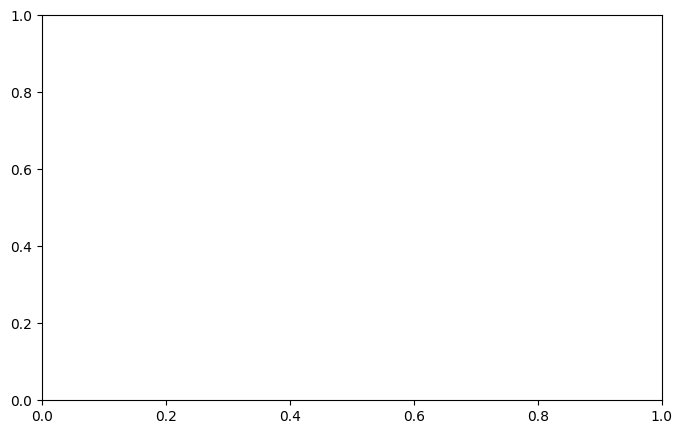

In [22]:
if __name__ == "__main__":
    main()